# 07 — Ensemble of the five tuned models
Combines the saved out-of-fold (train) and test probabilities of Logistic Regression, KNN, Random Forest, XGBoost and LightGBM. Nothing is re-tuned on the test set: ensemble weights and thresholds come from **out-of-fold train probabilities only**; the test set is scored once.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,roc_auc_score,average_precision_score,f1_score,precision_score,brier_score_loss,confusion_matrix,roc_curve)
pd.set_option('display.width',220,'display.max_columns',40); sns.set_theme(style='whitegrid'); SEED=42
ROOT=Path('..').resolve(); RES=ROOT/'results'; OUT=ROOT/'data'/'processed'
MODELS={'lr':'Logistic Regression','knn':'KNN','rf':'Random Forest','xgb':'XGBoost','lgbm':'LightGBM'}; TARGETS=['Cath','LAD','LCX','RCA']
df=pd.read_csv(OUT/'cad_clean.csv',keep_default_na=False); tr=df[df.split=='train']; te=df[df.split=='test']
Y_tr={t:tr[t].values for t in TARGETS}; Y_te={t:te[t].values for t in TARGETS}
oof={m:pd.read_csv(RES/f'{m}_oof_train_proba.csv') for m in MODELS}; tp={m:pd.read_csv(RES/f'{m}_test_proba.csv') for m in MODELS}
for m in MODELS: assert (oof[m].patient_idx.values==tr.patient_idx.values).all() and (tp[m].patient_idx.values==te.patient_idx.values).all()
print('loaded',list(MODELS))

loaded ['lr', 'knn', 'rf', 'xgb', 'lgbm']


## 1. Individual models on out-of-fold train probabilities

In [2]:
rows=[{'target':t,'model':MODELS[m],'oof_auc':roc_auc_score(Y_tr[t],oof[m][t]),'test_auc':roc_auc_score(Y_te[t],tp[m][t])} for t in TARGETS for m in MODELS]
ind=pd.DataFrame(rows); ind.pivot(index='model',columns='target',values='oof_auc').round(3).join(ind.pivot(index='model',columns='target',values='test_auc').round(3),rsuffix='_test')

target,Cath,LAD,LCX,RCA,Cath_test,LAD_test,LCX_test,RCA_test
model,,,,,,,,
KNN,0.924,0.864,0.716,0.740,0.898,0.779,0.767,0.673
LightGBM,0.955,0.869,0.745,0.759,0.916,0.787,0.723,0.659
Logistic Regression,0.948,0.871,0.725,0.741,0.928,0.762,0.754,0.665
Random Forest,0.934,0.859,0.739,0.749,0.917,0.827,0.753,0.632
XGBoost,0.952,0.869,0.734,0.738,0.920,0.791,0.712,0.640


## 2. Ensembles: simple mean, AUC-weighted mean, rank mean, logistic stacking

In [3]:
def thr_youden(y,p):
    f,t,th=roc_curve(y,p); return float(th[np.argmax(t-f)])
def thr_sens(y,p,s=0.95):
    f,t,th=roc_curve(y,p); return float(th[np.where(t>=s)[0][0]])
def metrics_at(y,p,thr):
    yh=(p>=thr).astype(int); tn,fp,fn,tp_=confusion_matrix(y,yh,labels=[0,1]).ravel(); se=tp_/(tp_+fn); sp=tn/(tn+fp)
    return dict(threshold=float(thr),accuracy=accuracy_score(y,yh),balanced_acc=(se+sp)/2,sensitivity=se,specificity=sp,precision=precision_score(y,yh,zero_division=0),
                f1=f1_score(y,yh),roc_auc=roc_auc_score(y,p),pr_auc=average_precision_score(y,p),brier=brier_score_loss(y,p))
def build(t):
    O=np.column_stack([oof[m][t] for m in MODELS]); T=np.column_stack([tp[m][t] for m in MODELS]); y=Y_tr[t]
    auc=np.array([roc_auc_score(y,O[:,i]) for i in range(O.shape[1])]); w=np.exp((auc-auc.max())*20); w/=w.sum()
    # rank mean (rank each model within its own set)
    rk=lambda A:np.column_stack([pd.Series(A[:,i]).rank(pct=True).values for i in range(A.shape[1])])
    lg=LogisticRegression(C=1.0,max_iter=2000); lo=lambda A:np.log(np.clip(A,1e-4,1-1e-4)/(1-np.clip(A,1e-4,1-1e-4)))
    oof_st=cross_val_predict(lg,lo(O),y,cv=StratifiedKFold(5,shuffle=True,random_state=SEED),method='predict_proba')[:,1]
    lg.fit(lo(O),y); te_st=lg.predict_proba(lo(T))[:,1]
    return {'mean':(O.mean(1),T.mean(1)),'auc-weighted':(O@w,T@w),'stack-logit':(oof_st,te_st)}, w
ens,weights={},{}
for t in TARGETS: ens[t],weights[t]=build(t)
pd.DataFrame(weights,index=list(MODELS)).round(3).rename_axis('AUC weights')

,Cath,LAD,LCX,RCA
AUC weights,,,,
lr,0.216,0.217,0.171,0.181
knn,0.134,0.191,0.145,0.176
rf,0.163,0.171,0.226,0.211
xgb,0.236,0.210,0.205,0.170
lgbm,0.251,0.212,0.254,0.262


In [4]:
rows=[]
for t in TARGETS:
    for name,(o,p) in ens[t].items():
        rows.append({'target':t,'ensemble':name,'oof_auc':roc_auc_score(Y_tr[t],o),'test_auc':roc_auc_score(Y_te[t],p)})
for t in TARGETS:
    best_single=ind[ind.target==t].sort_values('oof_auc').iloc[-1]
    rows.append({'target':t,'ensemble':'best single: '+best_single.model,'oof_auc':best_single.oof_auc,'test_auc':best_single.test_auc})
pd.DataFrame(rows).pivot(index='ensemble',columns='target',values=['oof_auc','test_auc']).round(3)

oof_auc                      test_auc                     
target                              Cath    LAD    LCX    RCA     Cath    LAD    LCX    RCA
ensemble                                                                                   
auc-weighted                       0.954  0.880  0.752  0.759    0.926  0.802  0.754  0.658
best single: LightGBM              0.955    NaN  0.745  0.759    0.916    NaN  0.723  0.659
best single: Logistic Regression     NaN  0.871    NaN    NaN      NaN  0.762    NaN    NaN
mean                               0.953  0.880  0.752  0.758    0.924  0.802  0.756  0.661
stack-logit                        0.954  0.865  0.719  0.750    0.922  0.780  0.743  0.661

## 3. Choose the ensemble per target by OOF AUC, then score the test set once

In [5]:
final,chosen=[],{}
for t in TARGETS:
    name=max(ens[t],key=lambda k:roc_auc_score(Y_tr[t],ens[t][k][0])); chosen[t]=name; o,p=ens[t][name]
    for rule,thr in {'default_0.5':0.5,'youden':thr_youden(Y_tr[t],o),'sens>=0.95':thr_sens(Y_tr[t],o,0.95)}.items():
        final.append({'target':t,'strategy':'ensemble:'+name,'threshold_rule':rule,**metrics_at(Y_te[t],p,thr)})
final=pd.DataFrame(final); final.to_csv(RES/'ensemble_test_metrics.csv',index=False); print(chosen)
final[['target','strategy','threshold_rule','threshold','accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc','brier']].round(3)

{'Cath': 'auc-weighted', 'LAD': 'auc-weighted', 'LCX': 'auc-weighted', 'RCA': 'auc-weighted'}


,target,strategy,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier
0,Cath,ensemble:auc-weighted,default_0.5,0.500,0.836,0.760,0.932,0.588,0.854,0.891,0.926,0.973,0.103
1,Cath,ensemble:auc-weighted,youden,0.635,0.885,0.866,0.909,0.824,0.930,0.920,0.926,0.973,0.103
2,Cath,ensemble:auc-weighted,sens>=0.95,0.449,0.836,0.760,0.932,0.588,0.854,0.891,0.926,0.973,0.103
3,LAD,ensemble:auc-weighted,default_0.5,0.500,0.754,0.737,0.833,0.640,0.769,0.800,0.802,0.857,0.177
4,LAD,ensemble:auc-weighted,youden,0.568,0.705,0.701,0.722,0.680,0.765,0.743,0.802,0.857,0.177
5,LAD,ensemble:auc-weighted,sens>=0.95,0.337,0.738,0.686,0.972,0.400,0.700,0.814,0.802,0.857,0.177
6,LCX,ensemble:auc-weighted,default_0.5,0.500,0.689,0.681,0.640,0.722,0.615,0.627,0.754,0.629,0.199
7,LCX,ensemble:auc-weighted,youden,0.369,0.689,0.706,0.800,0.611,0.588,0.678,0.754,0.629,0.199
8,LCX,ensemble:auc-weighted,sens>=0.95,0.227,0.574,0.633,0.960,0.306,0.490,0.649,0.754,0.629,0.199
9,RCA,ensemble:auc-weighted,default_0.5,0.500,0.574,0.564,0.522,0.605,0.444,0.480,0.658,0.599,0.222


## 4. Paper-style 3-way strategies with the ensemble probabilities

In [6]:
pL={t:ens[t][chosen[t]] for t in TARGETS}
thr={t:{'default_0.5':0.5,'youden':thr_youden(Y_tr[t],pL[t][0])} for t in TARGETS}
rows=[]
for rule in ('default_0.5','youden'):
    pred=np.zeros(len(te),int)
    for t in ['LAD','LCX','RCA']: pred|=(pL[t][1]>=thr[t][rule]).astype(int)
    y=Y_te['Cath']; tn,fp,fn,tp_=confusion_matrix(y,pred,labels=[0,1]).ravel()
    rows.append({'strategy':'ensemble OR-rule @'+rule,'accuracy':accuracy_score(y,pred),'sensitivity':tp_/(tp_+fn),'specificity':tn/(tn+fp),'roc_auc':roc_auc_score(y,1-np.prod([1-pL[t][1] for t in ['LAD','LCX','RCA']],axis=0))})
# stacking of vessel + CAD probabilities (OOF) into a final CAD model, paper Fig.1
Zo=np.column_stack([pL[t][0] for t in ['LAD','LCX','RCA','Cath']]); Zt=np.column_stack([pL[t][1] for t in ['LAD','LCX','RCA','Cath']])
lo=lambda A:np.log(np.clip(A,1e-4,1-1e-4)/(1-np.clip(A,1e-4,1-1e-4)))
fin=LogisticRegression(C=1.0,max_iter=2000); o2=cross_val_predict(fin,lo(Zo),Y_tr['Cath'],cv=StratifiedKFold(5,shuffle=True,random_state=SEED),method='predict_proba')[:,1]
fin.fit(lo(Zo),Y_tr['Cath']); p2=fin.predict_proba(lo(Zt))[:,1]
for rule,th in {'default_0.5':0.5,'youden':thr_youden(Y_tr['Cath'],o2),'sens>=0.95':thr_sens(Y_tr['Cath'],o2,0.95)}.items():
    m=metrics_at(Y_te['Cath'],p2,th); rows.append({'strategy':'ensemble stacked (paper FE) @'+rule,**{k:m[k] for k in ('accuracy','sensitivity','specificity','roc_auc')}})
for rule in ('default_0.5','youden','sens>=0.95'):
    m=final[(final.target=='Cath')&(final.threshold_rule==rule)].iloc[0]; rows.append({'strategy':'ensemble direct @'+rule,**{k:m[k] for k in ('accuracy','sensitivity','specificity','roc_auc')}})
paper=pd.DataFrame([{'strategy':'PAPER single (SVM)','accuracy':.850,'sensitivity':.894,'specificity':.768,'roc_auc':.81},{'strategy':'PAPER three-classifier (SVM)','accuracy':.810,'sensitivity':.814,'specificity':.798,'roc_auc':.87},
                    {'strategy':'PAPER feature engineering (SVM)','accuracy':.964,'sensitivity':1.0,'specificity':.881,'roc_auc':.92}])
cmp=pd.concat([paper,pd.DataFrame(rows)]).set_index('strategy'); cmp.round(3)

,accuracy,sensitivity,specificity,roc_auc
strategy,,,,
PAPER single (SVM),0.850,0.894,0.768,0.810
PAPER three-classifier (SVM),0.810,0.814,0.798,0.870
PAPER feature engineering (SVM),0.964,1.000,0.881,0.920
ensemble OR-rule @default_0.5,0.852,0.886,0.765,0.910
ensemble OR-rule @youden,0.836,0.864,0.765,0.910
ensemble stacked (paper FE) @default_0.5,0.852,0.932,0.647,0.922
ensemble stacked (paper FE) @youden,0.869,0.909,0.765,0.922
ensemble stacked (paper FE) @sens>=0.95,0.836,0.955,0.529,0.922
ensemble direct @default_0.5,0.836,0.932,0.588,0.926


## 5. Cross-model leaderboard (held-out test, Youden threshold) and nested-CV leaderboard (all 303 patients)

In [7]:
lb=[]
for m,nm in MODELS.items():
    d=pd.read_csv(RES/f'{m}_test_metrics_direct.csv'); d=d[d.threshold_rule=='youden']; d.insert(0,'model',nm); lb.append(d)
e=final[final.threshold_rule=='youden'].copy(); e.insert(0,'model','ENSEMBLE'); lb.append(e)
lb=pd.concat(lb); lb[['model','target','accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].round(3).sort_values(['target','roc_auc'],ascending=[True,False])

,model,target,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc
1,Logistic Regression,Cath,0.836,0.814,0.864,0.765,0.905,0.884,0.928,0.973
1,ENSEMBLE,Cath,0.885,0.866,0.909,0.824,0.930,0.920,0.926,0.973
1,XGBoost,Cath,0.869,0.837,0.909,0.765,0.909,0.909,0.920,0.970
1,Random Forest,Cath,0.869,0.873,0.864,0.882,0.950,0.905,0.917,0.967
1,LightGBM,Cath,0.820,0.749,0.909,0.588,0.851,0.879,0.916,0.967
1,KNN,Cath,0.836,0.814,0.864,0.765,0.905,0.884,0.898,0.962
4,Random Forest,LAD,0.754,0.749,0.778,0.720,0.800,0.789,0.827,0.877
4,ENSEMBLE,LAD,0.705,0.701,0.722,0.680,0.765,0.743,0.802,0.857
4,XGBoost,LAD,0.738,0.717,0.833,0.600,0.750,0.789,0.791,0.840
4,LightGBM,LAD,0.705,0.689,0.778,0.600,0.737,0.757,0.787,0.841


In [8]:
nest=pd.concat({MODELS[m]:pd.read_csv(RES/f'{m}_nested_cv.csv').set_index('target')[['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc']] for m in MODELS})
nest.round(3)

accuracy  balanced_acc  sensitivity  specificity  precision     f1  roc_auc
                    target                                                                             
Logistic Regression Cath       0.865         0.825        0.917        0.733      0.899  0.907    0.939
                    LAD        0.773         0.762        0.831        0.694      0.799  0.810    0.837
                    LCX        0.631         0.578        0.333        0.822      0.384  0.351    0.710
                    RCA        0.644         0.611        0.475        0.746      0.499  0.467    0.715
KNN                 Cath       0.819         0.830        0.807        0.853      0.941  0.863    0.920
                    LAD        0.736         0.733        0.758        0.708      0.790  0.766    0.838
                    LCX        0.648         0.657        0.698        0.615      0.582  0.609    0.724
                    RCA        0.633         0.629        0.613        0.646      0.534  0.545    0.711
Random Forest       Cath       0.872         0.848        0.903        0.793      0.920  0.910    0.928
                    LAD        0.776         0.761        0.847        0.676      0.787  0.814    0.836
                    LCX        0.667         0.637        0.498        0.777      0.606  0.527    0.723
                    RCA        0.650         0.632        0.553        0.711      0.565  0.534    0.715
XGBoost             Cath       0.872         0.844        0.908        0.781      0.916  0.910    0.933
                    LAD        0.740         0.732        0.767        0.697      0.787  0.772    0.826
                    LCX        0.630         0.614        0.538        0.690      0.525  0.527    0.668
                    RCA        0.676         0.659        0.587        0.731      0.598  0.582    0.719
LightGBM            Cath       0.855         0.812        0.912        0.711      0.895  0.900    0.935
                    LAD        0.780         0.766        0.847        0.684      0.794  0.817    0.849
                    LCX        0.631         0.601        0.462        0.739      0.537  0.489    0.679
                    RCA        0.679         0.650        0.527        0.773      0.598  0.552    0.710

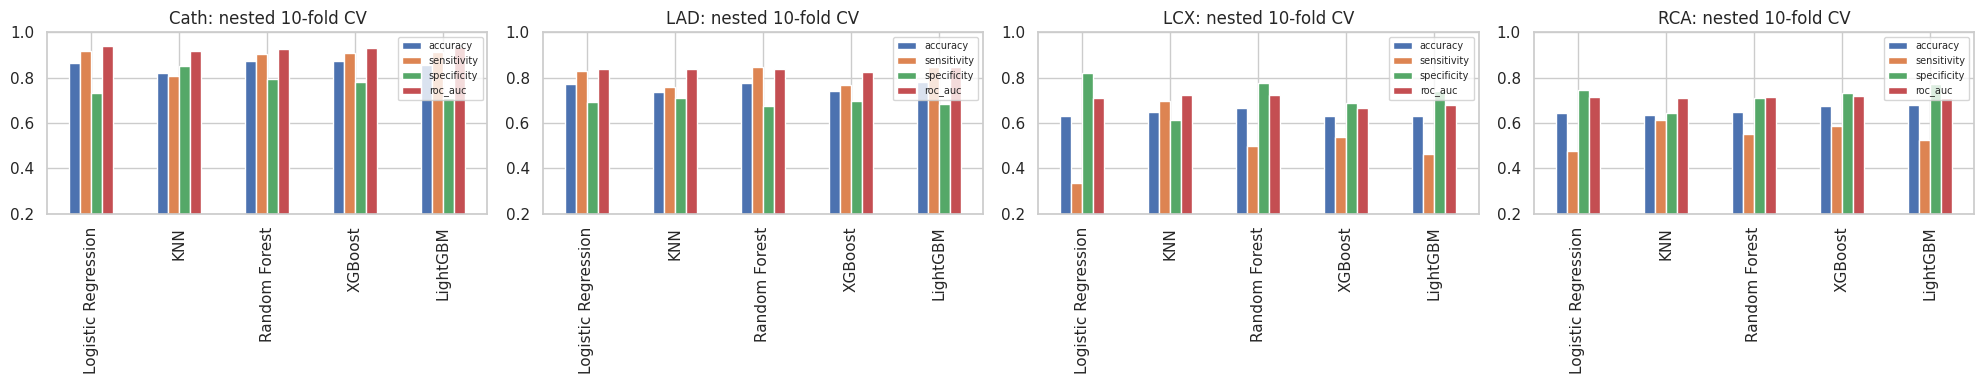

In [9]:
fig,axes=plt.subplots(1,4,figsize=(20,4))
for ax,t in zip(axes,TARGETS):
    d=nest.xs(t,level=1); d[['accuracy','sensitivity','specificity','roc_auc']].plot.bar(ax=ax); ax.set_title(f'{t}: nested 10-fold CV'); ax.set_ylim(0.2,1); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(RES/'figures'/'ensemble_nested_leaderboard.png',dpi=110); plt.show()

In [10]:
nest.to_csv(RES/'nested_cv_leaderboard.csv'); lb.to_csv(RES/'test_leaderboard.csv',index=False); cmp.to_csv(RES/'paper_comparison_cath.csv'); print('saved')

saved
